# Weekly Planning Models

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
BASE = Path.cwd()
if not (BASE / "evidence").exists():
    BASE = BASE / "notebooks" 
assert (BASE / "evidence").is_dir(), "Open from the project root or notebooks."
EVIDENCE = BASE / "evidence"
def read_json(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8-sig"))
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})


## Separate prediction questions
Bookings: Calendar service-like entries in the next two weeks. Appointment hours: booked team-slot duration in the next week. These are not completed treatments or productive employee-hours. Regression uses error metrics, not classification precision/accuracy.

The algorithms and input formulas are fixed in `config/cp2_planning_v1.json`. They refit weekly only on earlier matured windows. Historical comparisons repeatedly examined Calendar snapshots; new live outcomes must be reported separately.

Target,Algorithm,Inputs,Assessment windows,MAE,RMSE,WAPE (%),Baseline MAE,MAE reduction (%)
booking_entries_h2,extra_trees_w1000_activity_calendar_weather,36,13,12.76,18.15,9.02,20.73,38.46
booked_hours_h1,ridge_100_w78_activity_calendar,32,14,8.97,10.37,10.76,11.77,23.76


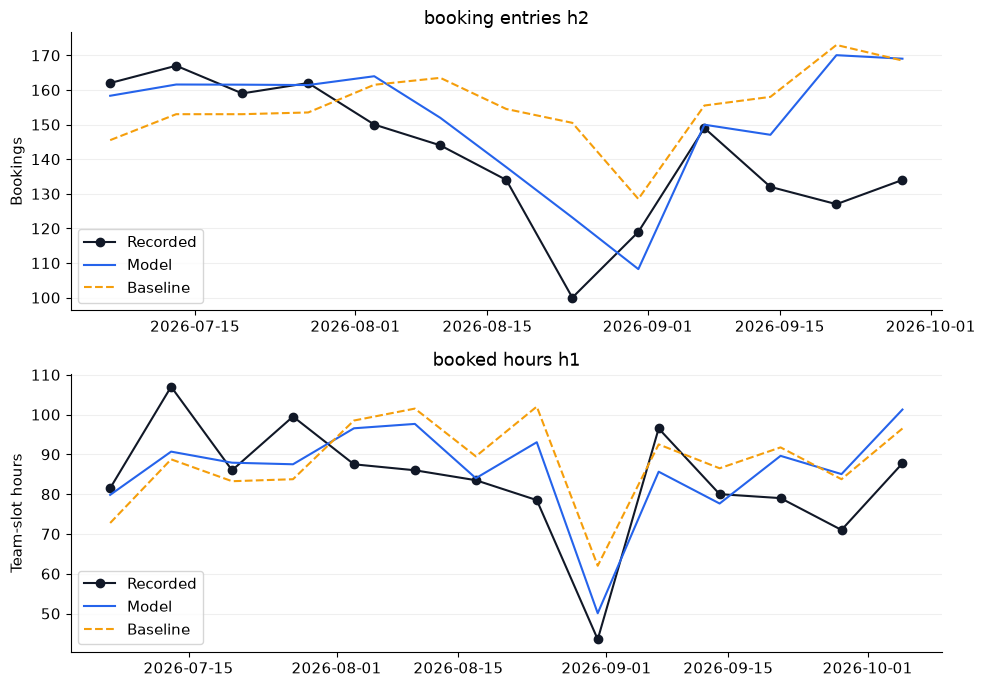

In [2]:
protocol = read_json("planning_protocol.json")
rows=[]
for task in protocol["targets"]:
    recorded = pd.read_csv(EVIDENCE / (task["task"]+"_assessment.csv"))
    error = recorded.selected - recorded.actual
    baseline_error = recorded.baseline - recorded.actual
    mae=error.abs().mean(); baseline_mae=baseline_error.abs().mean()
    assert abs(mae-task["assessment"]["mae"])<1e-6
    rows.append({"Target":task["task"], "Algorithm":task["selected"]["id"], "Inputs":task["input_count"],
                 "Assessment windows":len(recorded),"MAE":mae,"RMSE":(error.pow(2).mean())**.5,
                 "WAPE (%)":100*error.abs().sum()/recorded.actual.abs().sum(),"Baseline MAE":baseline_mae,
                 "MAE reduction (%)":100*(1-mae/baseline_mae)})
display(pd.DataFrame(rows).round(2))
fig,axes=plt.subplots(2,1,figsize=(10,7))
for ax,task in zip(axes,protocol["targets"]):
    recorded=pd.read_csv(EVIDENCE/(task["task"]+"_assessment.csv"))
    dates=pd.to_datetime(recorded.origin)
    ax.plot(dates,recorded.actual,label="Recorded",color="#111827",marker="o")
    ax.plot(dates,recorded.selected,label="Model",color="#2563eb")
    ax.plot(dates,recorded.baseline,label="Baseline",color="#f59e0b",linestyle="--")
    ax.set_title(task["task"].replace("_"," "));ax.set_ylabel("Bookings" if task["target"]=="booking_entries" else "Team-slot hours")
    ax.legend();ax.grid(axis="y",alpha=.2)
plt.tight_layout();plt.show()

## Inputs and partitions
Activity lags use earlier weekly booking counts and appointment hours. Rolling means, variation, trend, calendar seasonality and festival inputs are defined in the source. The booking candidate also uses earlier weather. The table retains the exact input names so the reported counts are traceable.

In [3]:
display(pd.read_csv(EVIDENCE / "exact_input_names.csv"))
display(pd.read_csv(EVIDENCE / "partitions_and_use.csv"))

study,input_set,field
Returns,compact,service_number
Returns,compact,package_sessions_recorded
Returns,compact,sale_total_rm
Returns,compact,days_since_previous_service
Returns,compact,days_sale_to_anchor
Returns,compact,prior_package_warranty_claims
Returns,compact,prior_package_service_events
Returns,compact,prior_property_warranty_claims
Returns,compact,prior_property_service_events
Returns,compact,days_since_prior_property_claim


Study,Train,Validation,Assessment,Why useful
Planning forecasts,Earlier timestamp-matured weeks; 52 / 78 / all history,"12 one-week or 10 two-week origins, Jan–Jun 2026; labels and latest edits before 6 July","14 one-week or 13 overlapping two-week origins, Jul–Oct 2026","Plan rosters, appointment slots and supplies. Appointment hours are not technician effort."
Pest-related return targets,Earlier mature rows; assessment property/programme groups reserved before selection,"Up to 3 earlier periods in Jul 2025–Mar 2026, all labels mature before 1 April",1 April–15 July 2026: 976 all-service / 225 third-visit / 270 final-visit rows,Investigate treatment follow-up risk; formal warranty eligibility stays a separate rule.
Monthly repurchase,Mature earlier customer-months; features use only purchases before each month,"Earlier 2025 folds, labels mature before 2026 assessment",Jan–Apr 2026 month-start landmarks; overlapping future purchase windows,Forecast repeat business; not enough evidence for customer-specific alerts.
Enquiry to recorded sale,"Jan–Mar 2026: 7,447 contacts / 142 later sale matches","May–Jun 2026: 3,171 / 64, with gaps for 30-day label maturity","Aug–16 Sep 2026: 1,021 / 30, phone-disjoint; same-day ambiguity excluded","Would help enquiry conversion, but current source labels and results are weak."
New DOSM inputs,"Same 1,506 grouped earlier services as existing larger study","Same 1,177 Jul–Nov 2025 services; calibration and threshold chosen here","Same 2,075 Jan–Aug 2026 services, already inspected historically","Test whether dated local context adds value; income is district context, not customer income."


## Management use
Compare the forecast with staff-entered whole-week team-slot capacity and the actual advance bookings. Inspect the team/day booking heatmap, then record a scheduling decision. No model automatically cancels or assigns appointments.

Source code: `scripts/research_management_forecasts_20261021_v2.py` builds time-safe matrices and the historical comparison. `scripts/planning_engine.py` and `scripts/cp2_planning_job.py` implement the frozen weekly protocol. The live first origin is 26 October; this document does not claim the first natural scheduled run has occurred.